This code explains Multi-head attention algorithm

In [ ]:
pip install torch gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 40.8 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import gensim.downloader as api
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

1. Multi-Head Attention Module (Algorithm 12.2 from Bishop)

In [ ]:
class MultiHeadAttentionAlgorithm(nn.Module):
    def __init__(self, D, H, D_v):
        """
        D   : Input embedding dimension (For this model, D = 50)
        H   : Number of parallel attention heads (For this model, H = 5 you can vary it based on this formula: D_v = D/H)
        D_v : Projection dimension for Value matrices (per head)
        """
        super(MultiHeadAttentionAlgorithm, self).__init__()
        self.D = D
        self.H = H
        self.D_v = D_v

        # Parallel projection matrices per head (Without bias to mimic pure matrix multiplication)
        self.W_q = nn.ModuleList([nn.Linear(D, D, bias=False) for _ in range(H)])
        self.W_k = nn.ModuleList([nn.Linear(D, D, bias=False) for _ in range(H)])
        self.W_v = nn.ModuleList([nn.Linear(D, D_v, bias=False) for _ in range(H)])

        # Final output weight matrix W^(o) -> Shape: (H * D_v, D)
        self.W_o = nn.Linear(H * D_v, D, bias=False)

        # Dictionary to store weights for visualization
        self.saved_attention_maps = {}

    def attention(self, Q_h, K_h, V_h, head_idx):
        # Algorithm 12.1: Attention(Q, K, V) = softmax( (Q * K^T) / sqrt(D) ) * V
        scores = torch.matmul(Q_h, K_h.transpose(-2, -1)) / (self.D ** 0.5)
        attention_weights = F.softmax(scores, dim=-1)

        # Save the N x N attention matrix for plotting later
        self.saved_attention_maps[head_idx] = attention_weights.detach().numpy()

        return torch.matmul(attention_weights, V_h)

    def forward(self, X):
        heads = []

        # for h = 1; ... ; H do
        for h in range(self.H):
            Q_h = self.W_q[h](X)  # Qh = X * W_(q)_h
            K_h = self.W_k[h](X)  # Kh = X * W_(k)_h
            V_h = self.W_v[h](X)  # Vh = X * W_(v)_h

            H_h = self.attention(Q_h, K_h, V_h, head_idx=h)  # Hh = Attention(Qh; Kh; Vh)
            heads.append(H_h)

        # H = Concat [H1; ... ; HN]
        H_concat = torch.cat(heads, dim=-1)

        # return Y(X) = H * W_(o)
        Y = self.W_o(H_concat)
        return Y

The glove-wiki-gigaword-50 is a pre-trained 50-dimensional word embedding model trained on a 6-billion token corpus combining Wikipedia 2014 and Gigaword 5.

In [ ]:
# Dataset Loading & Text Execution Pipeline

if __name__ == "__main__":

    # Load the pre-trained glove-wiki-gigaword-50 via gensim API
    # (Note: This will download a ~65MB file on the first run)
    print("Loading pre-trained 'glove-wiki-gigaword-50' dataset...")
    glove_vectors = api.load("glove-wiki-gigaword-50")
    print("Dataset successfully loaded!\n")

    # Sample text sequence to encode
    sentence = "neural networks compute attention matrix values"
    tokens = sentence.lower().split()
    N = len(tokens)

    print(f"Input Sentence: '{sentence}'")
    print(f"Sequence Length (N): {N} tokens\n")

    # Create Vector Matrix X from GloVe Embeddings
    D = 50  # GloVe model forced structural restriction
    X_list = []

    for word in tokens:
        if word in glove_vectors:
            # Get the static 50-dimensional numpy array from GloVe
            word_vector = glove_vectors[word]
            X_list.append(torch.tensor(word_vector, dtype=torch.float32))
        else:
            # Fallback for out-of-vocabuEnforcedlary terms (Zero vector fallback strategy)
            print(f"Warning: '{word}' not found in GloVe. Initialising with zeros.")
            X_list.append(torch.zeros(D, dtype=torch.float32))

    # Stack individual row vectors into a unified Input Matrix X
    X = torch.stack(X_list)  # Shape: (N, D) -> (6, 50)

    print("--- Input Matrix X (Static GloVe Space) ---")
    print(f"Matrix X Shape: {X.shape} (N tokens × D dimension)")
    print(f"Vector for the token '{tokens[2]}':\n{X[2][:10]}... (showing first 10 dims)\n")

    # Hyperparameters Configuration for Multi-Head Attention
    H = 5    # Let's use 5 parallel attention heads
    D_v = 10 # Value projection dimension per head (H * D_v = 50)

    # Initialize model pipeline
    mha_model = MultiHeadAttentionAlgorithm(D=D, H=H, D_v=D_v)

    # Process matrix X through Multi-Head Attention Pipeline
    Y = mha_model(X)  # Shape: (N, D) -> (6, 50)

    print("--- Output Matrix Y (Contextual Attention Space) ---")
    print(f"Matrix Y Shape: {Y.shape} (N tokens × D dimension)")
    print(f"Contextualized vector for '{tokens[2]}':\n{Y[2][:10].detach().numpy()}... (showing first 10 dims)")


Loading pre-trained 'glove-wiki-gigaword-50' dataset...
[==================================================] 100.0% 66.0/66.0MB downloaded
Dataset successfully loaded!

Input Sentence: 'neural networks compute attention matrix values'
Sequence Length (N): 6 tokens

--- Input Matrix X (Static GloVe Space) ---
Matrix X Shape: torch.Size([6, 50]) (N tokens × D dimension)
Vector for the token 'compute':
tensor([ 0.6336, -0.3800,  1.1517,  0.1029,  0.5602, -0.3308,  0.7809, -0.5294,
         0.3601,  0.0498])... (showing first 10 dims)

--- Output Matrix Y (Contextual Attention Space) ---
Matrix Y Shape: torch.Size([6, 50]) (N tokens × D dimension)
Contextualized vector for 'compute':
[-0.38032523 -0.06972888  0.04591617 -0.25776526  0.00252503  0.09655246
 -0.04868471  0.15177688 -0.06345917  0.09304728]... (showing first 10 dims)


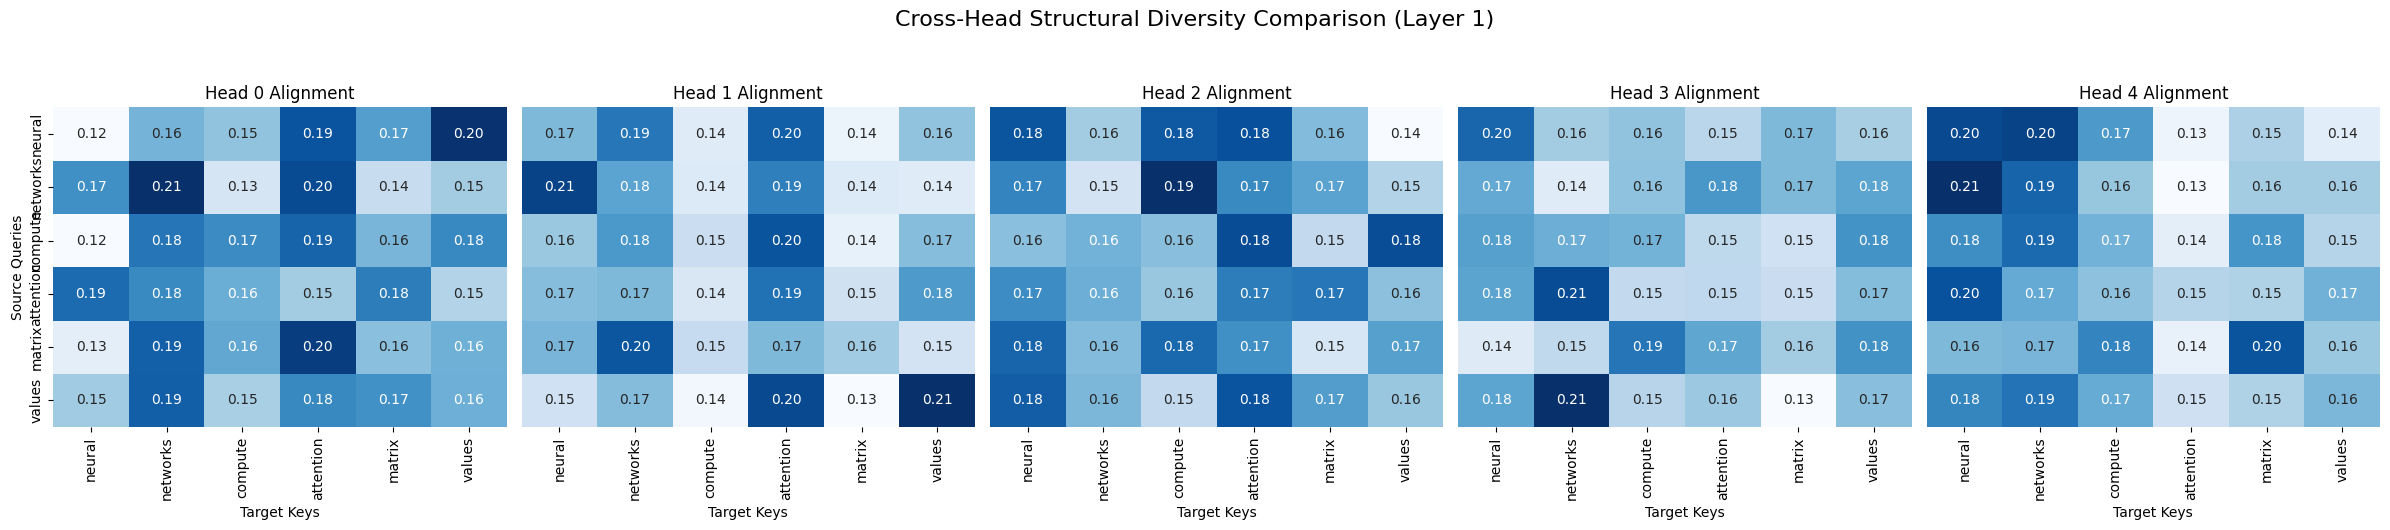

In [ ]:
# Ensure gradients are turned off for extraction tracking
with torch.no_grad():

    fig, axes = plt.subplots(1, 5, figsize=(24, 5))

    # Iterate through all heads stored inside your model's tracking memory
    # (Assuming you added a dictionary to save weights like we did in the previous step)
    for h in range(5):
        # Extract the N x N causal attention matrix for head h
        attention_map = mha_model.saved_attention_maps[h]

        # Plot individual heatmaps side-by-side
        sns.heatmap(
            attention_map,
            annot=True,          # Show exact weights inside the active cells
            fmt=".2f",           # Clean 2-decimal point formatting
            cmap="Blues",        # Visual continuity with deep blue hues
            cbar=False,          # Turn off side color bars to save space
            xticklabels=tokens,  # Key tokens (Targets)
            yticklabels=tokens if h == 0 else False, # Only show source words on the far left plot
            ax=axes[h]
        )

        axes[h].set_title(f"Head {h} Alignment")
        axes[h].set_xlabel("Target Keys")
        if h == 0:
            axes[h].set_ylabel("Source Queries")

    # Clean and project layout boundaries
    plt.suptitle("Cross-Head Structural Diversity Comparison (Layer 1)", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()


Comparing two sentences with same words but different placing

In [ ]:
# Create two sentences with identical words but opposite meanings
sentence1 = ["the", "dog", "bit", "the", "man"]
sentence2 = ["the", "man", "bit", "the", "dog"]

# Look up their static GloVe vectors
X1 = torch.stack([torch.tensor(glove_vectors[w]) for w in sentence1])
X2 = torch.stack([torch.tensor(glove_vectors[w]) for w in sentence2])

# Pass both through the non-positional model
Y1 = mha_model(X1)
Y2 = mha_model(X2)

bit_vector_A = Y1[2].detach().numpy()
bit_vector_B = Y2[2].detach().numpy()

absolute_diff = np.abs(bit_vector_A - bit_vector_B)
# Check the output vector for the word "bit" (index 2 in both sentences)
# They will be EXACTLY identical, proving the model cannot see sentence structure!
print(torch.allclose(Y1[2], Y2[2]))  # Returns: True (Complete failure to distinguish meaning)

True


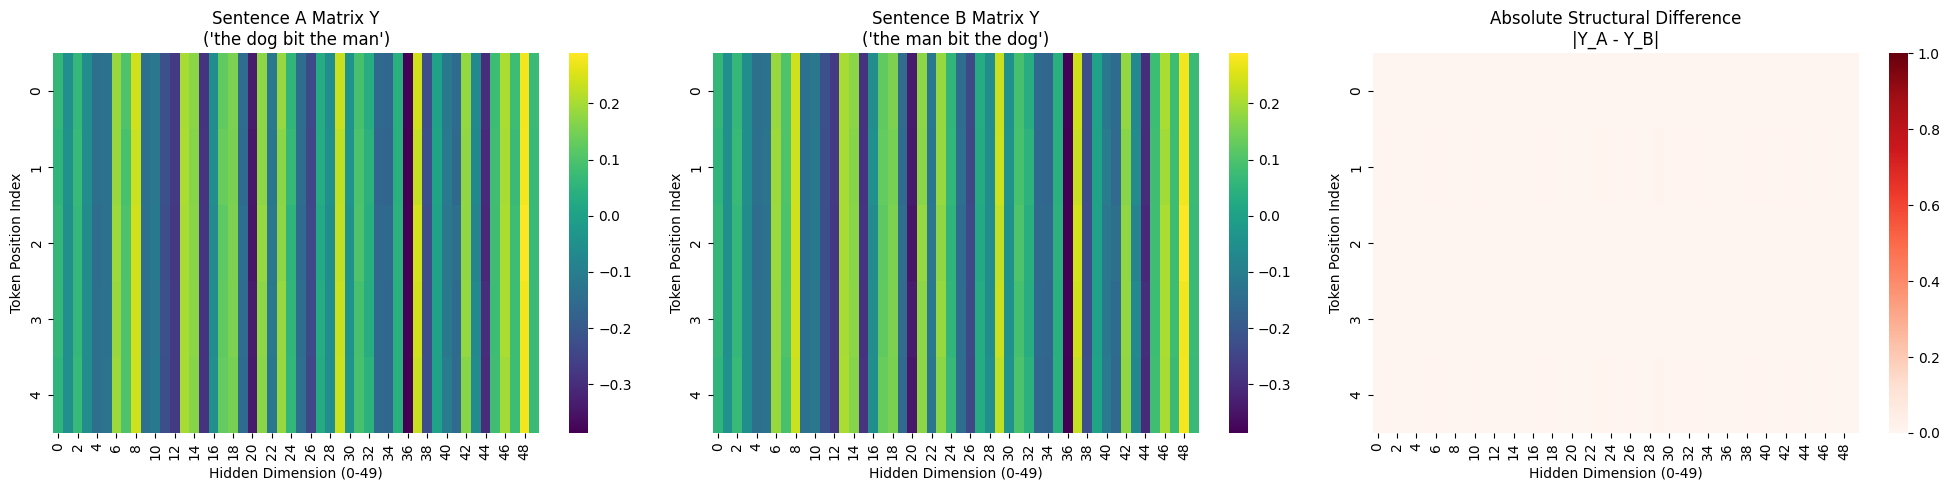

In [ ]:
# Convert the full sequence outputs to numpy arrays
matrix_A = Y1.detach().numpy()
matrix_B = Y2.detach().numpy()

# Calculate the pixel-by-pixel structural difference matrix
difference_matrix = np.abs(matrix_A - matrix_B)

# Set up a triple-panel plotting landscape
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Panel 1: Sentence A Output Landscape
sns.heatmap(matrix_A, cmap="viridis", cbar=True, ax=axes[0])
axes[0].set_title("Sentence A Matrix Y\n('the dog bit the man')")
axes[0].set_ylabel("Token Position Index")
axes[0].set_xlabel("Hidden Dimension (0-49)")

# Panel 2: Sentence B Output Landscape
sns.heatmap(matrix_B, cmap="viridis", cbar=True, ax=axes[1])
axes[1].set_title("Sentence B Matrix Y\n('the man bit the dog')")
axes[1].set_ylabel("Token Position Index")
axes[1].set_xlabel("Hidden Dimension (0-49)")

# Panel 3: The Absolute Variance Breakdown (The Proof)
sns.heatmap(difference_matrix, cmap="Reds", cbar=True, ax=axes[2], vmin=0, vmax=1)
axes[2].set_title("Absolute Structural Difference\n|Y_A - Y_B|")
axes[2].set_ylabel("Token Position Index")
axes[2].set_xlabel("Hidden Dimension (0-49)")

plt.tight_layout()
plt.show()
